# 02 Validity checks

**Plan section:** 4. **Label:** supporting (pre-condition for the confirmatory test in `03_ate`).

Four checks that the experiment was run correctly. Only `treatment`, `exposure` and the features `f0`–`f11` are loaded. **No outcomes (`visit`, `conversion`) are used here.**

| # | Check | Flag rule (fixed in advance) |
|---|---|---|
| 1 | Sample ratio mismatch: chi-square vs. 85/15 | p < 0.001 (also report observed share and deviation) |
| 2 | Covariate balance: SMD per feature | \|SMD\| > 0.1 material; > 0.02 minor |
| 3 | Joint balance: 5-fold CV AUC of a classifier predicting `treatment` | mean AUC > 0.55 (deviation #1) |
| 4 | Exposure integrity: exposure rate per arm | any exposure in control |

### Memo wording if a check fails (written before running the checks)

- **SRM flagged:** "The observed treatment share was X% against an intended 85%. The deviation is larger than chance would produce, so some users may have been lost or added non-randomly. Effect estimates are reported, but should be read alongside the feature-adjusted (Lin) estimates." If the deviation is under 0.1 pp, the memo also says it is too small to plausibly bias the effect materially.
- **SMD material (> 0.1):** "Treatment and control differ on feature(s) … by more than 0.1 standard deviations, likely from pooling several tests with different ratios. The recommendation relies on the feature-adjusted (Lin) estimate."
- **SMD minor only (0.02–0.1):** noted in the memo's risks section; no change to the headline estimate.
- **Balance AUC > 0.55:** "The features can partly predict treatment assignment (AUC = X), so the arms are not exchangeable on observables. The recommendation relies on the feature-adjusted estimate."
- **Control exposure > 0:** "X control users were shown the ad, so the ITT effect is diluted (biased toward zero)." The size of the contamination is reported.

In [1]:
import pandas as pd

from uplift.config import EXPOSURE, FEATURES, TREATMENT
from uplift.data import load_processed
from uplift.io import write_results
from uplift.plots import love_plot, save_fig
from uplift.sql import run_sql
from uplift.validity import balance_auc, exposure_by_arm, smd_table, srm_test

In [2]:
arm_counts = run_sql("arm_counts")
df = load_processed([*FEATURES, TREATMENT, EXPOSURE])
arm_counts

,treatment,n,exposures
0,0,2096937,0
1,1,11882655,428212


## 1. Sample ratio mismatch

In [3]:
counts = arm_counts.set_index("treatment")["n"]
srm = srm_test(n_treatment=counts[1], n_control=counts[0])
pd.Series(srm)

n_treatment        11882655
n_control           2096937
observed_share         0.85
expected_share         0.85
deviation_pp       0.000013
deviation_in_se    0.001348
chi2               0.000002
p_value            0.998924
flag                  False
dtype: object

## 2. Covariate balance (SMD)

In [4]:
smd = smd_table(df, FEATURES)
smd.round(4)

,mean_t,mean_c,sd_t,sd_c,smd,abs_smd,label
feature,,,,,,,
f0,19.6148,19.6517,5.3756,5.3881,-0.0069,0.0069,balanced
f1,10.0703,10.0679,0.1067,0.0930,0.0240,0.0240,minor
f2,8.4463,8.4482,0.2991,0.3007,-0.0062,0.0062,balanced
f3,4.1694,4.2328,1.3524,1.2420,-0.0488,0.0488,minor
f4,10.3392,10.3365,0.3441,0.3387,0.0080,0.0080,balanced
f5,4.0266,4.0393,0.4370,0.3955,-0.0306,0.0306,minor
f6,-4.1828,-3.9999,4.6009,4.4420,-0.0404,0.0404,minor
f7,5.1056,5.0803,1.2125,1.1633,0.0213,0.0213,minor
f8,3.9334,3.9347,0.0569,0.0554,-0.0224,0.0224,minor


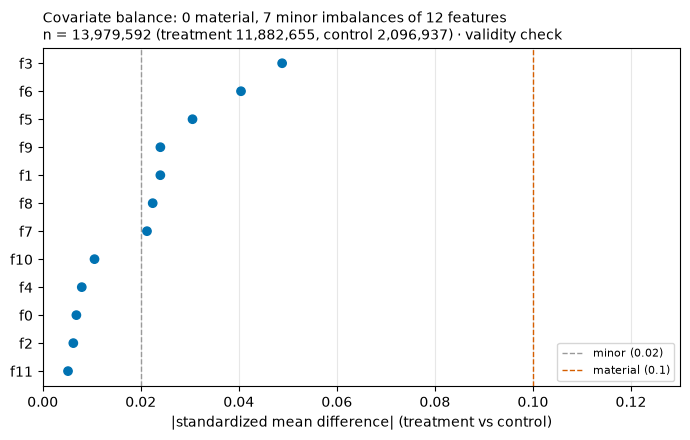

In [5]:
n_material = int((smd["label"] == "material").sum())
n_minor = int((smd["label"] == "minor").sum())
fig = love_plot(
    smd,
    title=f"Covariate balance: {n_material} material, {n_minor} minor imbalances of 12 features",
    subtitle=f"n = {len(df):,} (treatment {counts[1]:,}, control {counts[0]:,}) · validity check",
)
save_fig(fig, "smd_love_plot");

## 3. Joint balance (classifier AUC)

Gradient boosting with the plan's fixed hyperparameters, 5-fold stratified CV, seed 42. Takes about 1–2 minutes.

In [6]:
auc = balance_auc(df[list(FEATURES)], df[TREATMENT])
pd.Series(auc)

fold_aucs         [0.510334, 0.510894, 0.510608, 0.51081, 0.510348]
mean_auc                                                   0.510599
sd_auc                                                     0.000257
flag_threshold                                                 0.55
flag                                                          False
dtype: object

## 4. Exposure integrity

In [7]:
exposure = exposure_by_arm(arm_counts)
pd.DataFrame({arm: exposure[arm] for arm in ("treatment", "control")})

,treatment,control
n,1.188266e+07,2096937.0
exposed,4.282120e+05,0.0
exposure_rate,3.603673e-02,0.0


## Summary

In [8]:
max_smd = f"max |SMD| = {smd['abs_smd'].max():.4f} ({smd['abs_smd'].idxmax()})"
control_rate = f"control exposure rate = {exposure['control']['exposure_rate']:.5f}"
summary = pd.DataFrame(
    [
        ("SRM", f"share {srm['observed_share']:.5f}, p = {srm['p_value']:.3g}", srm["flag"]),
        ("SMD", max_smd, n_material > 0),
        ("Balance AUC", f"mean AUC = {auc['mean_auc']:.4f} ± {auc['sd_auc']:.4f}", auc["flag"]),
        ("Exposure", control_rate, exposure["flag"]),
    ],
    columns=["check", "result", "flagged"],
).set_index("check")

write_results(
    "validity",
    {
        "srm": srm,
        "smd": smd.reset_index().to_dict(orient="records"),
        "smd_n_material": n_material,
        "smd_n_minor": n_minor,
        "balance_auc": auc,
        "exposure": exposure,
        "any_flag": bool(summary["flagged"].any()),
    },
)
summary

,result,flagged
check,,
SRM,"share 0.85000, p = 0.999",False
SMD,max |SMD| = 0.0488 (f3),False
Balance AUC,mean AUC = 0.5106 ± 0.0003,False
Exposure,control exposure rate = 0.00000,False


## Interpretation

**No check is flagged. The experiment passes validity, and `03_ate` proceeds with the unadjusted ITT estimate as the primary analysis.**

1. **SRM: pass, but uninformative.** The observed treatment share is 0.85000 (11,882,655 / 13,979,592), within 0.001 standard errors of 85% (p ≈ 0.999). That is closer than random assignment would typically land; usual noise is about ±1 SE. The likely reason is that Criteo sub-sampled the released file to an exact 85/15 ratio. So this check confirms the file matches its documentation, but it cannot detect problems in the original assignment. Checks 2 and 3 carry more weight here.
2. **SMD: pass, with 7 minor imbalances.** No feature exceeds 0.1. Seven features (`f1`, `f3`, `f5`, `f6`, `f7`, `f8`, `f9`) fall in the 0.02–0.1 "minor" band; the largest is `f3` at −0.049. Several also differ in spread between arms (e.g., `f3` SD 1.35 vs. 1.24), consistent with pooling several tests with different populations. Per the pre-written wording, this goes in the memo's risks section with no change to the headline estimate.
3. **Balance AUC: pass, with a small but real signal.** Mean AUC = 0.511, well under the 0.55 flag. The folds agree closely (SD 0.0003), so the 0.011 gap above 0.50 is not noise: the features carry a small amount of information about assignment, matching the minor SMD imbalances. It is far too weak to drive large biases, but it is the reason for the feature-adjusted (Lin) estimate cross-check in `05_cuped`.
4. **Exposure: pass.** No control user was exposed (0 of 2,096,937). 3.60% of treated users were actually shown an ad (428,212 of 11,882,655). That exposure rate `e` drives cost and break-even calculations later.